# Ranking Grid Cells for Landmine Survey in Antioquia, Colombia

**Author:** Travis Carlson

**Dataset:** *Landmine Detection in Antioquia, Colombia*, the RELand landmine-risk dataset on Hugging Face ([mdulcer10/landmine-detection](https://huggingface.co/datasets/mdulcer10/landmine-detection)), CC BY 4.0, released with Dulce Rubio et al. (2024)

This notebook builds and tests supervised machine learning models that estimate landmine risk for 500 × 500 m grid cells in 15 municipalities of Antioquia, Colombia, all since declared mine-free. Each of the 26,761 cells is labelled 1 if it intersects "at least one confirmed hazardous area or a cleared area where landmines were found during humanitarian demining operations" (dataset card), and 0 otherwise: 430 cells (1.6%) are mine cells. The 63 features are open data on each cell and its municipality: distances to roads, settlements, coca crops and past landmine events, terrain, climate, land use, population and municipal statistics.

**Problem.** Supervised binary classification: predict `mines_outcome` (1 = mines found, 0 = clear) from the 63 features. The models' scores rank a municipality's cells for survey, so the question is how well a model trained on other municipalities ranks the cells of one it has never seen, which is where such a model would be used (Dulce Rubio et al., 2024).

**Approach.** Two classifiers, logistic regression and gradient-boosted trees, both weighted for the 1.6% mine rate. Each municipality is held out in turn: the model is tuned and trained on the other 14 and scores the 15th. The models are compared with two rankings that need no training (a random order, and nearest-past-event-first), trained again without the distance to past events, checked against one random split, and compared with the published RELand benchmark.

**How the sections map to the brief.** Section 2 loads and inspects the data (Task 2); sections 3 and 4 explore and preprocess it (Task 3); section 5 sets out how the models are tested and section 6 trains them (Task 4); sections 7 and 8 evaluate them (Task 5); section 9 shows what the logistic regression weighs; section 10 is the summary (Task 6).

**Data handling.** The two coordinate columns are read once, in section 2.3, for two counts; they are then dropped and never reach a model, a table or a chart. The dataset card warns that predictions "should **not** be used as the sole basis for demining operations without expert human review and validation in the field".

*References cited in this notebook:*
- Dulce Rubio, M., Zeng, S., Wang, Q., Alvarado, D., Moreno Rivera, F., Heidari, H., & Fang, F. (2024). RELand: Risk estimation of landmines via interpretable invariant risk minimization. *ACM Journal on Computing and Sustainable Societies, 2*(2), 1–29. https://doi.org/10.1145/3648437
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. In *Advances in Neural Information Processing Systems 30* (pp. 3146–3154).
- Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein, S., Lahoz-Monfort, J. J., Schröder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F., & Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), Article e0118432. https://doi.org/10.1371/journal.pone.0118432

## 1. Problem and data

### 1.1 Setup

Libraries, the data file and its provenance, fixed settings, and the chart style of the earlier projects. The workflow uses Python, NumPy, Pandas, SciPy, scikit-learn and Matplotlib.

In [1]:
import hashlib
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import scipy
from scipy import stats
from scipy.spatial import cKDTree
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import auc, average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV, GroupKFold, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

pd.set_option("display.max_columns", 70)
pd.set_option("display.width", 120)

# Files (the data file sits in the same folder as this notebook)
DATA_FILE = Path("landmine_detection.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Provenance of the data file: the dataset's Parquet file, converted to CSV with no change to its values
DATASET_PAGE = "https://huggingface.co/datasets/mdulcer10/landmine-detection"
SOURCE_PATH = "data/train-00000-of-00001.parquet"
REVISION = "30710e43dc447ee95bce30e9ed264f68e454e00c"
DOWNLOADED_ON = "2026-10-18"
SOURCE_SHA256 = "e18e6a278cc62336ff13a68342f5d8a848aebb5e4b35e0cc64dc654160090337"    # the Parquet file as downloaded
EXPECTED_SHA256 = "f2ba3b981487ae3879175db4521bc1c6d02352d1053dc9889715eb5e703fe371"  # landmine_detection.csv

# Columns with a special role
COORDS = ["LATITUD_Y", "LONGITUD_X"]  # read once in section 2.3, then dropped
GROUP, TARGET = "Municipio", "mines_outcome"

# Fixed settings
SEED = 0          # one seed for every random step, so each run gives the same results
TOP_SHARE = 0.10  # share of each municipality's cells flagged for survey in the top-10% scores

# Municipality names as the dataset card spells them (the file stores them in capitals)
CARD_NAMES = ["Abejorral", "Alejandría", "Chigorodó", "Cocorná", "El Carmen de Viboral", "Granada",
              "La Unión", "Nariño", "Sabanalarga", "San Carlos", "San Francisco", "San Luis",
              "San Rafael", "San Roque", "Sonsón"]
DISPLAY_NAME = {name.upper(): name for name in CARD_NAMES}

# Chart style: light surface, quiet grid, neutrals for the data and one fixed colour per ranking
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
COLOURS = {"Random ranking": MUTED, "Distance rule": "#1baf7a",
           "Logistic regression": "#2a78d6", "Gradient-boosted trees": "#eb6834"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-",
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "font.size": 10, "lines.linewidth": 2, "legend.frameon": False,
})


def save_fig(fig, name):
    """Save a figure to the figures folder at print resolution and return its path."""
    path = FIG_DIR / name
    fig.savefig(path, dpi=200, bbox_inches="tight")
    return path


for name, module in [("pandas", pd), ("numpy", np), ("scipy", scipy),
                     ("scikit-learn", sklearn), ("matplotlib", matplotlib)]:
    print(f"{name:<13} {module.__version__}")

pandas        3.0.6
numpy         2.5.4
scipy         1.18.1
scikit-learn  1.9.1
matplotlib    3.11.2


### 1.2 The dataset

The dataset was published on Hugging Face with the RELand study of landmine risk in Colombia (Dulce Rubio et al., 2024), under a CC BY 4.0 licence. Its card describes it this way:
- **Cells:** 15 municipalities of Antioquia, which "have been declared mine-free after comprehensive humanitarian demining operations", divided into 26,761 grid cells of 500 × 500 m.
- **Labels:** a cell is positive if it "intersects at least one confirmed hazardous area or a cleared area where landmines were found during humanitarian demining operations, using data from Colombia's National Mine Action Center (AICMA)"; the other cells "have been thoroughly inspected and declared free of mines". The labels therefore come from completed demining rather than estimates.
- **Features:** 63 "derived from multiple open geospatial, socio-economic, and conflict-related data sources".
- **Testing:** the card suggests "Geographic block cross-validation ... using municipalities as spatial blocks: train on a subset of municipalities and validate on held-out ones, simulating deployment to a new territory."

It meets the brief's dataset rules: tabular, in a CSV file (section 2.1), public and licensed for academic use, real rather than synthetic, with a clear binary target, and different from the datasets of Projects 1 and 2 (Colombia's landmine victims register and its record of demining results). It comes from Hugging Face rather than one of the four sources the brief lists; the card links it to its peer-reviewed study and gives its licence, origin and testing protocol.

## 2. Load and inspect

### 2.1 Load the data file

The data file, `landmine_detection.csv`, is the dataset's only data file converted from Parquet to CSV with pandas; no row, column or value was changed. The original Parquet file is kept unchanged beside it, and the README gives the command used; this notebook reads only the CSV. The CSV's SHA-256 checksum is compared with the one recorded when it was made, so anyone rerunning the notebook can confirm they are using the same data. Decimal numbers are read with pandas' round-trip converter (`float_precision="round_trip"`), which gives back every value exactly as it is in the Parquet file; pandas' default converter reads 182 of them one or two units off in the last binary digit. The first rows are shown without the two coordinate columns (see Data handling, above).

In [2]:
def file_sha256(path):
    """Return the SHA-256 checksum of a file, reading it in 1 MB chunks.

    Used to confirm that the data file is the snapshot recorded when it was made.
    A different checksum means a newer download or a changed file.
    """
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


checksum = file_sha256(DATA_FILE)
print(f"Dataset page:   {DATASET_PAGE}")
print(f"Source file:    {SOURCE_PATH} at revision {REVISION}")
print(f"Downloaded on:  {DOWNLOADED_ON}")
print(f"Source SHA-256: {SOURCE_SHA256}")
print(f"Data file:      {DATA_FILE} (the source file converted to CSV, values unchanged)")
print(f"CSV SHA-256:    {checksum}")
if checksum == EXPECTED_SHA256:
    print("Checksum matches the recorded snapshot.")
else:
    print("WARNING: checksum differs from the recorded snapshot; results may not match the report.")

# The round-trip converter reads every decimal value exactly as written in the file
df_raw = pd.read_csv(DATA_FILE, float_precision="round_trip")
print(f"\nLoaded {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.drop(columns=COORDS).head()

Dataset page:   https://huggingface.co/datasets/mdulcer10/landmine-detection
Source file:    data/train-00000-of-00001.parquet at revision 30710e43dc447ee95bce30e9ed264f68e454e00c
Downloaded on:  2026-10-18
Source SHA-256: e18e6a278cc62336ff13a68342f5d8a848aebb5e4b35e0cc64dc654160090337
Data file:      landmine_detection.csv (the source file converted to CSV, values unchanged)
CSV SHA-256:    f2ba3b981487ae3879175db4521bc1c6d02352d1053dc9889715eb5e703fe371
Checksum matches the recorded snapshot.



Loaded 26,761 rows x 67 columns


,Municipio,mines_outcome,elevation,rainfall,temperature,population_2012,No. Víctimas por Declaración,airports_dist,seaport_dist,settlement_dist,finance_dist,edu_dist,buildings_dist,waterways_dist,coca_dist,dist_roads_t1,dist_roads_t2,dist_roads_t3,dist_old_mine,soil_texture15_trans1,soil_texture15_trans2,nighttime_lights_2012,hist_mines,retro_pobl_tot,indrural,areaoficialkm2,altura,discapital,pib_percapita_cons,land_use_Agroforestal,land_use_Agrícola,land_use_Conservación de Suelos,land_use_Cuerpo de agua,land_use_Forestal,land_use_Ganadera,land_use_Zonas urbanas,weather_Cuerpo de agua,weather_Cálido húmedo,weather_Cálido húmedo a muy húmedo,weather_Cálido muy húmedo,weather_Cálido seco,weather_Cálido seco a húmedo,weather_Frío húmedo,weather_Frío húmedo a muy húmedo,weather_Frío húmedo y frío muy húmedo,weather_Frío muy húmedo,weather_Muy frío y muy húmedo,weather_Templado húmedo a muy húmedo,weather_Zona urbana,relief_Abanicos aluviales subactuales y recientes,"relief_Abanicos aluvio-torrenciales, abanicoterrazas y glacís subrecientes y antiguos",relief_Cuerpo de agua,relief_Espinazos,relief_Espinazos y colinas,relief_Filas y vigas,relief_Glacís coluvial y coluvios de remoción,relief_Glacís y coluvios de remoción,relief_Lomas y colinas,relief_Plano de inundación,relief_Plano de inundación y terrazas bajas,relief_Terrazas,relief_Terrazas y abanicos terrazas,relief_Vallecitos,relief_Vallecitos coluvio-aluviales,relief_Zona urbana
0,CHIGORODÓ,0,8.321069,76.104863,27.0,24.528168,48175,19.194549,39.655619,5.571759,14.920146,9.712803,0.436186,0.067567,24.901704,17.391914,8.031022,13.885556,14.503779,-0.589368,-0.272355,0.0,12.0,48017.0,0.142951,615,31.0,189.134933,7.396802,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
1,CHIGORODÓ,0,8.812821,79.864412,27.0,42.277782,48175,17.264668,42.126817,7.420439,15.066498,9.256411,1.380861,0.260521,25.610123,16.740306,10.410064,14.066805,14.769123,-0.588898,-0.223477,0.0,12.0,48017.0,0.142951,615,31.0,189.134933,7.396802,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
2,CHIGORODÓ,0,7.932982,77.527988,27.0,42.277782,48175,16.895245,42.621386,7.833282,15.144992,9.243559,1.837258,0.152477,25.722864,16.651828,10.880046,13.741084,14.871926,-1.130906,-0.395634,0.0,12.0,48017.0,0.142951,615,31.0,189.134933,7.396802,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
3,CHIGORODÓ,0,7.177505,80.659765,27.0,46.937914,48175,14.527711,40.988684,10.926273,16.121791,9.885362,0.239270,0.001683,25.190396,16.448207,14.214778,11.350489,16.013928,-1.436796,-0.143082,0.0,12.0,48017.0,0.142951,615,31.0,189.134933,7.396802,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
4,CHIGORODÓ,0,6.599792,68.592699,27.0,45.104572,48175,13.661605,39.542358,12.317430,16.747234,10.509545,0.386426,0.062822,24.601717,16.586849,15.661970,10.516407,16.704217,-1.513291,-0.173490,0.0,12.0,48017.0,0.142951,615,31.0,189.134933,7.396802,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0


### 2.2 Columns and data types

The 67 columns fall into seven groups. The one-hot columns are the dataset's encoding of three categorical variables (land use, climate zone and relief type): each column is 1 if the cell belongs to that class and 0 otherwise.

In [3]:
ONEHOT_PREFIXES = {"land use": "land_use_", "climate": "weather_", "relief": "relief_"}


def column_group(column):
    """Return the group a column belongs to: coordinates, municipality, target, continuous or a one-hot group."""
    if column in COORDS:
        return "coordinates"
    if column == GROUP:
        return "municipality"
    if column == TARGET:
        return "target"
    for group, prefix in ONEHOT_PREFIXES.items():
        if column.startswith(prefix):
            return f"one-hot: {group}"
    return "continuous feature"


groups_table = (pd.DataFrame({"group": df_raw.columns.map(column_group), "dtype": df_raw.dtypes.astype(str)})
                .groupby("group", sort=False)
                .agg(columns=("dtype", "size"), dtypes=("dtype", lambda s: ", ".join(sorted(set(s))))))
print(f"Columns: {len(df_raw.columns)}; features: "
      f"{groups_table.drop(['coordinates', 'municipality', 'target'])['columns'].sum()}")
groups_table

Columns: 67; features: 63


,columns,dtypes
group,,
coordinates,2,float64
municipality,1,str
target,1,int64
continuous feature,27,"float64, int64"
one-hot: land use,7,int64
one-hot: climate,13,int64
one-hot: relief,16,int64


In [4]:
CONTINUOUS = [c for c in df_raw.columns if column_group(c) == "continuous feature"]
ONEHOT_GROUPS = {group: [c for c in df_raw.columns if c.startswith(prefix)]
                 for group, prefix in ONEHOT_PREFIXES.items()}
ONEHOT = [c for columns in ONEHOT_GROUPS.values() for c in columns]
print(f"Continuous features ({len(CONTINUOUS)}):")
print(df_raw[CONTINUOUS].dtypes.to_string())
for group, columns in ONEHOT_GROUPS.items():
    print(f"\nOne-hot {group} ({len(columns)}): {', '.join(c.removeprefix(ONEHOT_PREFIXES[group]) for c in columns)}")
print(f"\nMunicipalities in the file: {df_raw[GROUP].nunique()}")

Continuous features (27):
elevation                       float64
rainfall                        float64
temperature                     float64
population_2012                 float64
No. Víctimas por Declaración      int64
airports_dist                   float64
seaport_dist                    float64
settlement_dist                 float64
finance_dist                    float64
edu_dist                        float64
buildings_dist                  float64
waterways_dist                  float64
coca_dist                       float64
dist_roads_t1                   float64
dist_roads_t2                   float64
dist_roads_t3                   float64
dist_old_mine                   float64
soil_texture15_trans1           float64
soil_texture15_trans2           float64
nighttime_lights_2012           float64
hist_mines                      float64
retro_pobl_tot                  float64
indrural                        float64
areaoficialkm2                    int64
altura        

The continuous features, as the dataset card describes them (units and sources from the card). Eight of them, marked *(municipality)*, have one value per municipality.

| Column | Description | Unit | Source |
|---|---|---|---|
| `elevation` | Elevation | m above sea level | WorldClim (2023) |
| `rainfall` | Average annual rainfall | mm | WorldClim (2023) |
| `temperature` | Average temperature | °C | WorldClim (2023) |
| `population_2012` | Population estimate for the grid cell (2012) | people | WorldPop (2023) |
| `No. Víctimas por Declaración` | Declared conflict victims *(municipality)* | people | Victims Unit (2019) |
| `airports_dist`, `seaport_dist`, `settlement_dist` | Distance to the nearest airport, seaport, settlement | km | OpenStreetMap (2022) |
| `finance_dist`, `edu_dist`, `buildings_dist` | Distance to the nearest financial institution, school, building | km | OpenStreetMap (2022) |
| `waterways_dist` | Distance to the nearest waterway | km | OpenStreetMap (2022) |
| `coca_dist` | Distance to the nearest coca cultivation area | km | UNODC (2021) |
| `dist_roads_t1`, `dist_roads_t2`, `dist_roads_t3` | Distance to the nearest primary, secondary, tertiary road | km | IGAC (2023) |
| `dist_old_mine` | Distance to the nearest historical landmine accident | km | DAICMA (2022) |
| `soil_texture15_trans1`, `soil_texture15_trans2` | Soil texture components (ILR-transformed) | — | Varón-Ramírez et al. (2022) |
| `nighttime_lights_2012` | Night-time light intensity (2012) | index 0–63 | Li et al. (2020) |
| `hist_mines` | Historical landmine accidents *(municipality)* | incidents | DAICMA (2022) |
| `retro_pobl_tot` | Total population *(municipality)* | people | Acevedo & Bornacelly (2014) |
| `indrural` | Rural index *(municipality)* | 0 = urban, 1 = fully rural | Acevedo & Bornacelly (2014) |
| `areaoficialkm2` | Official area *(municipality)* | km² | Acevedo & Bornacelly (2014) |
| `altura` | Average altitude *(municipality)* | m | Acevedo & Bornacelly (2014) |
| `discapital` | Distance to the departmental capital, Medellín *(municipality)* | km | Acevedo & Bornacelly (2014) |
| `pib_percapita_cons` | GDP per capita at 2009 constant prices *(municipality)* | millions of pesos | Acevedo & Bornacelly (2014) |

**Data quality checks:** empty cells, repeated rows, one class per cell in each one-hot group, values that cannot be negative, and the target.

In [5]:
print(f"Empty cells: {df_raw.isna().sum().sum()}")
print(f"Rows that repeat another row exactly: {df_raw.duplicated().sum()}")

for group, columns in ONEHOT_GROUPS.items():
    classes_per_cell = df_raw[columns].sum(axis=1).value_counts().sort_index()
    print(f"Cells by number of {group} classes: {classes_per_cell.to_dict()}")

unclassed = df_raw[df_raw[ONEHOT_GROUPS["climate"] + ONEHOT_GROUPS["relief"]].sum(axis=1) == 0]
print(f"\nCells with no climate and no relief class: {len(unclassed)}; mine cells among them: "
      f"{unclassed[TARGET].sum()}; by municipality: "
      f"{unclassed[GROUP].map(DISPLAY_NAME).value_counts().to_dict()}")

distance_like = [c for c in CONTINUOUS if "dist" in c or c == "discapital"] + ["population_2012", "nighttime_lights_2012"]
print(f"\nSmallest value among the {len(distance_like)} distance, population and light features: "
      f"{df_raw[distance_like].min().min()}")
assert set(df_raw[GROUP].unique()) == set(DISPLAY_NAME), "unexpected municipality name"

counts = df_raw[TARGET].value_counts().sort_index()
print(f"\nTarget mines_outcome: {counts[0]:,} clear cells (0) and {counts[1]:,} mine cells (1); "
      f"mine rate {counts[1] / len(df_raw):.2%}")

Empty cells: 0
Rows that repeat another row exactly: 0
Cells by number of land use classes: {1: 26761}
Cells by number of climate classes: {0: 27, 1: 26734}
Cells by number of relief classes: {0: 27, 1: 26734}

Cells with no climate and no relief class: 27; mine cells among them: 0; by municipality: {'Sonsón': 20, 'Nariño': 4, 'Abejorral': 3}

Smallest value among the 15 distance, population and light features: 0.0

Target mines_outcome: 26,331 clear cells (0) and 430 mine cells (1); mine rate 1.61%


**What the checks show.**
- No cell is empty and no row repeats another. The data types fit the columns: every feature and the target are numbers (integers for the target, the 0/1 columns, declared victims and official area; decimals for the rest), and the municipality is text.
- Every cell has exactly one land-use class. 27 cells (Sonsón 20, Nariño 4, Abejorral 3) have no climate and no relief class; none is a mine cell. They stay in, with those two groups at 0.
- No distance, population or light value is negative, which the log transform in section 4.2 relies on.
- The target is heavily imbalanced: 430 mine cells against 26,331 clear cells (1.61%).
- Three errors in the dataset card, none of which affects the file: the card heads its tables "30" continuous and "33" one-hot columns and lists "13" relief categories before naming 16, while the file has 27, 36 and 16 (63 features, as the card says); and its loading example names `cmpatino/landmine-detection`, which Hugging Face did not find on 2026-10-18. This notebook reads the downloaded file directly.
- The file stores municipality names in capitals; tables and charts use the card's spelling.

### 2.3 Coordinate checks, then drop the coordinates

This is the one use of the coordinates. Each cell's centre is given as latitude and longitude, and two counts need them: cells that share a centre (repeated cells), and mine cells with another mine cell among their eight neighbours, which shows how clustered mine cells are and matters for how the models are tested (section 3.3). The centres are converted to metres with an equirectangular approximation, close enough at this scale, and a cell's neighbours are those whose centres lie within 750 m: the four side neighbours are about 500 m away, the four corner neighbours about 707 m, and the next ring starts at about 1,000 m. Only the two counts are printed. The coordinates are then dropped.

In [6]:
EARTH_RADIUS_M = 6_371_000
NEIGHBOUR_RADIUS_M = 750


def coordinate_checks(raw):
    """Return the number of repeated cell centres and of mine cells with a mine cell among their eight neighbours."""
    repeated = int(raw.duplicated(COORDS).sum())
    lat = np.deg2rad(raw["LATITUD_Y"].to_numpy())
    lon = np.deg2rad(raw["LONGITUD_X"].to_numpy())
    xy = np.column_stack([lon * EARTH_RADIUS_M * np.cos(lat.mean()), lat * EARTH_RADIUS_M])
    mine_xy = xy[raw[TARGET].to_numpy() == 1]
    # Count each mine cell's mine-cell neighbours; the cell itself is within the radius, so subtract 1
    mine_neighbours = cKDTree(mine_xy).query_ball_point(mine_xy, r=NEIGHBOUR_RADIUS_M, return_length=True) - 1
    return repeated, int((mine_neighbours > 0).sum()), len(mine_xy)


repeated_cells, clustered_mines, n_mines = coordinate_checks(df_raw)
print(f"Cells that share a centre with another cell: {repeated_cells}")
print(f"Mine cells with at least one mine cell among their eight neighbours: "
      f"{clustered_mines} of {n_mines} ({clustered_mines / n_mines:.1%})")

df = df_raw.drop(columns=COORDS)
del df_raw
print(f"\nCoordinates dropped; working table: {df.shape[0]:,} rows x {df.shape[1]} columns")

Cells that share a centre with another cell: 0
Mine cells with at least one mine cell among their eight neighbours: 372 of 430 (86.5%)

Coordinates dropped; working table: 26,761 rows x 65 columns


No two cells share a centre. 372 of the 430 mine cells (86.5%) touch another mine cell: mine cells come in clusters, which section 3.3 returns to.

## 3. Explore

Five questions before modelling: how mine cells are spread across municipalities, how far they lie from past landmine events, how clustered they are, what the municipality-wide features carry, and which features overlap.

### 3.1 Mine cells by municipality

In [7]:
by_municipality = (df.groupby(GROUP)[TARGET].agg(cells="size", mine_cells="sum")
                   .rename(index=DISPLAY_NAME).rename_axis("municipality"))
by_municipality["mine rate %"] = (by_municipality["mine_cells"] / by_municipality["cells"] * 100).round(2)
by_municipality = by_municipality.sort_values("mine_cells", ascending=False)
by_municipality

,cells,mine_cells,mine rate %
municipality,,,
Sonsón,5461,86,1.57
Granada,773,79,10.22
San Carlos,2911,50,1.72
Nariño,1287,49,3.81
San Rafael,1478,38,2.57
El Carmen de Viboral,1716,34,1.98
San Francisco,1450,27,1.86
Cocorná,980,26,2.65
San Luis,1728,16,0.93


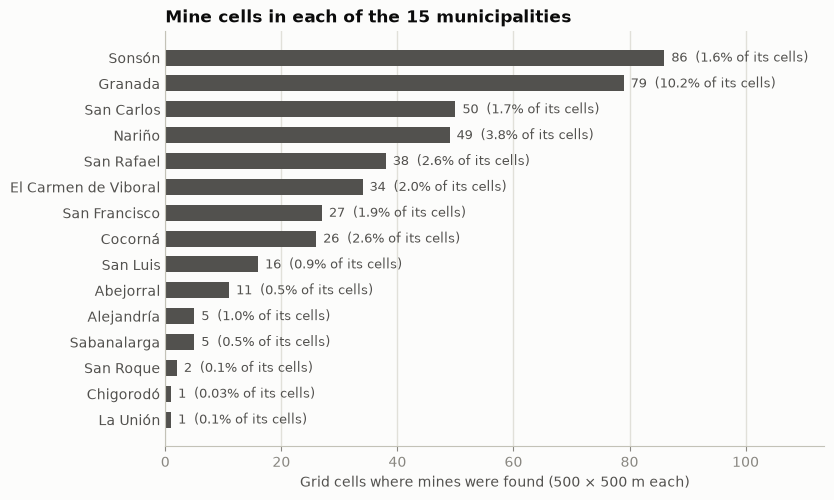

In [8]:
order = by_municipality.sort_values("mine_cells")
fig, ax = plt.subplots(figsize=(8.5, 5.4))
ax.barh(order.index, order["mine_cells"], color=INK_2, height=0.62)
for position, (count, rate) in enumerate(zip(order["mine_cells"], order["mine rate %"])):
    shown_rate = f"{rate:.1f}%" if rate >= 0.1 else f"{rate:.2f}%"  # keep Chigorodó's 0.03% from showing as 0.0%
    ax.text(count + 1.2, position, f"{count}  ({shown_rate} of its cells)", va="center", color=INK_2, fontsize=9)
ax.set_title("Mine cells in each of the 15 municipalities")
ax.set_xlabel("Grid cells where mines were found (500 × 500 m each)")
ax.set_xlim(0, order["mine_cells"].max() * 1.32)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0, labelcolor=INK_2)
save_fig(fig, "01_mine_cells_by_municipality.png")
plt.show()

Mine cells range from 1 (Chigorodó, La Unión) to 86 (Sonsón), and the mine rate from 0.03% (Chigorodó) to 10.2% (Granada). Three municipalities have only 1 or 2 mine cells (Chigorodó, La Unión, San Roque), so a score computed on one of them rests on one or two cells; section 7 reports results both over all 15 and over the 12 with at least 5 mine cells.

### 3.2 Distance to past landmine events

How well does each continuous feature, taken alone, separate mine cells from clear cells? The measure is the ROC-AUC of the feature's values: the chance that a randomly chosen mine cell has a higher value than a randomly chosen clear cell (0.5 is no better than chance). For each feature the direction that separates better is used, for example nearer rather than farther.

In [9]:
def single_feature_auc(values, target):
    """Return the ROC-AUC of one feature used as a score, and the direction (higher or lower) that gives it."""
    higher = roc_auc_score(target, values)
    return (higher, "higher") if higher >= 0.5 else (1 - higher, "lower")


separation = pd.DataFrame([(column, *single_feature_auc(df[column], df[TARGET])) for column in CONTINUOUS],
                          columns=["feature", "ROC-AUC alone", "mine cells have"]).set_index("feature")
separation.sort_values("ROC-AUC alone", ascending=False).head(6).round(3)

,ROC-AUC alone,mine cells have
feature,,
dist_old_mine,0.919,lower
seaport_dist,0.672,higher
airports_dist,0.668,higher
hist_mines,0.646,higher
rainfall,0.644,higher
dist_roads_t2,0.643,higher


Mine cells within 1 km of a past event: 384 of 430 (89.3%)
Clear cells within 1 km of a past event: 5,509 of 26,331 (20.9%)
Mine rate within 1 km: 6.52%; beyond 1 km: 0.22%
Median distance: mine cells 0.33 km, clear cells 2.17 km


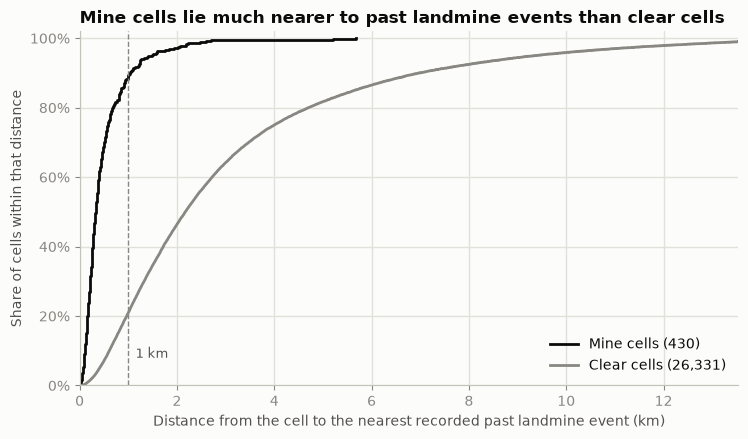

In [10]:
mine = df[TARGET] == 1
near = df["dist_old_mine"] <= 1
print(f"Mine cells within 1 km of a past event: {(mine & near).sum()} of {mine.sum()} ({(mine & near).sum() / mine.sum():.1%})")
print(f"Clear cells within 1 km of a past event: {(~mine & near).sum():,} of {(~mine).sum():,} "
      f"({(~mine & near).sum() / (~mine).sum():.1%})")
print(f"Mine rate within 1 km: {df.loc[near, TARGET].mean():.2%}; beyond 1 km: {df.loc[~near, TARGET].mean():.2%}")
print(f"Median distance: mine cells {df.loc[mine, 'dist_old_mine'].median():.2f} km, "
      f"clear cells {df.loc[~mine, 'dist_old_mine'].median():.2f} km")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
limit = df["dist_old_mine"].quantile(0.99)
for label, mask, colour in [(f"Mine cells ({mine.sum()})", mine, INK),
                            (f"Clear cells ({(~mine).sum():,})", ~mine, MUTED)]:
    values = np.sort(df.loc[mask, "dist_old_mine"].to_numpy())
    share = np.arange(1, len(values) + 1) / len(values)
    ax.step(values, share, where="post", color=colour, label=label)
ax.axvline(1, color=MUTED, linewidth=1, linestyle="--")
ax.text(1.15, 0.08, "1 km", color=INK_2, fontsize=9)
ax.set_title("Mine cells lie much nearer to past landmine events than clear cells")
ax.set_xlabel("Distance from the cell to the nearest recorded past landmine event (km)")
ax.set_ylabel("Share of cells within that distance")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(0, limit)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right")
save_fig(fig, "02_distance_to_past_events.png")
plt.show()

Taken alone, `dist_old_mine` separates mine cells from clear cells far better than any other feature: a randomly chosen mine cell lies nearer a past event than a randomly chosen clear cell 91.9% of the time, against 67.2% for the next feature, `seaport_dist` (mine cells lie farther from the seaport). 384 of the 430 mine cells (89.3%) lie within 1 km of a past event, against 20.9% of clear cells, so the mine rate is 6.52% within 1 km and 0.22% beyond. The median mine cell is 0.33 km from a past event, the median clear cell 2.17 km.

This feature may share a source with the labels. Both come from Colombia's mine action records, which have "systematically" recorded "georeferenced historical landmine events since 1990" (Dulce Rubio et al., 2024, Section 3), and no statement was found on whether the events predate the demining behind the labels. If some events were recorded during that demining, part of the feature's strength would restate the labels rather than predict them. Every model is therefore also trained without it (section 4.5).

### 3.3 How clustered are the mine cells?

Section 2.3 found that 372 of the 430 mine cells (86.5%) have another mine cell among their eight neighbours. If cells were split at random into training and test sets, most test mine cells would have a neighbour in the training set, and a model could score well by recognising the surroundings of known contaminated areas. That measures something easier than ranking the cells of a new municipality: with spatially structured data, random splits overstate how well a model transfers to new places, and blocks of whole areas give a fairer test (Roberts et al., 2017). The models are therefore tested on held-out municipalities (section 5), and one random split is run as a check of how much it would flatter them (section 8).

### 3.4 Municipality-wide features

Eight features have a single value in each municipality. Do they track how contaminated each municipality is? The measure is the Spearman rank correlation, over the 15 municipalities, between each feature and the municipality's mine rate.

In [11]:
MUNICIPALITY_WIDE = [c for c in CONTINUOUS if df.groupby(GROUP)[c].nunique().max() == 1]
municipality_rates = df.groupby(GROUP)[TARGET].mean()
rows = []
for column in MUNICIPALITY_WIDE:
    values = df.groupby(GROUP)[column].first()
    result = stats.spearmanr(values, municipality_rates.loc[values.index])
    rows.append({"feature": column, "distinct values": values.nunique(),
                 "Spearman ρ with mine rate": result.statistic, "p-value": result.pvalue})
print(f"Features with one value per municipality: {len(MUNICIPALITY_WIDE)}")
pd.DataFrame(rows).set_index("feature").round(3)

Features with one value per municipality: 8


,distinct values,Spearman ρ with mine rate,p-value
feature,,,
No. Víctimas por Declaración,15,0.214,0.443
hist_mines,14,0.665,0.007
retro_pobl_tot,15,-0.321,0.243
indrural,15,0.300,0.277
areaoficialkm2,15,-0.289,0.296
altura,15,0.146,0.603
discapital,15,-0.054,0.850
pib_percapita_cons,15,0.125,0.657


Seven of the eight take a different value in each of the 15 municipalities, so any one of them identifies the municipality; `hist_mines` takes 14 values, because two municipalities have the same count. Only `hist_mines`, the municipality's count of historical landmine accidents, tracks the municipalities' mine rates (Spearman ρ = 0.66, p = .007, n = 15); none of the others comes near significance. When a municipality is held out, all its cells share these values. In the logistic regression, which adds up weighted features, a shared value moves all the municipality's scores together and cannot change the order of its cells; the trees can combine it with other features, so for them it can, through patterns learned from the other 14.

### 3.5 Land use and overlapping features

In [12]:
land_use = (df.groupby(TARGET)[ONEHOT_GROUPS["land use"]].sum().T
            .rename(columns={0: "clear cells", 1: "mine cells"}))
land_use.index = land_use.index.str.removeprefix("land_use_")
land_use["mine rate %"] = (land_use["mine cells"] / (land_use["mine cells"] + land_use["clear cells"]) * 100).round(2)
display(land_use.sort_values("mine cells", ascending=False))

elevation_temperature = stats.spearmanr(df["elevation"], df["temperature"]).statistic
print(f"Spearman ρ between elevation and temperature: {elevation_temperature:.3f}")

mines_outcome,clear cells,mine cells,mine rate %
Forestal,19377,413,2.09
Agrícola,5356,14,0.26
Cuerpo de agua,216,1,0.46
Ganadera,794,1,0.13
Zonas urbanas,43,1,2.27
Conservación de Suelos,21,0,0.00
Agroforestal,524,0,0.00


Spearman ρ between elevation and temperature: -0.993


413 of the 430 mine cells lie in forest land, where 2.09% of the 19,790 cells are mine cells, and 14 in agricultural land (0.26% of 5,370). Elevation and temperature are almost the same variable in reverse (Spearman ρ = −0.993), so a linear model can share their joint effect between them in many ways; section 9 reads their weights together.

## 4. Preprocess

### 4.1 Features, target and groups

The 63 features are the 27 continuous and 36 one-hot columns. The target is `mines_outcome`. `Municipio` is not a feature: it defines which cells are held out together when the models are tested (section 5). There are no missing values to fill and no categorical text to encode, since the dataset already one-hot encodes its three categorical variables.

In [13]:
FEATURES_63 = CONTINUOUS + ONEHOT
FEATURES_62 = [c for c in FEATURES_63 if c != "dist_old_mine"]
X, y, groups = df[FEATURES_63], df[TARGET], df[GROUP]
print(f"Features: {len(FEATURES_63)} ({len(CONTINUOUS)} continuous, {len(ONEHOT)} one-hot); "
      f"without dist_old_mine: {len(FEATURES_62)}")
print(f"Cells: {len(X):,}; mine cells: {y.sum()}; municipalities: {groups.nunique()}")

Features: 63 (27 continuous, 36 one-hot); without dist_old_mine: 62
Cells: 26,761; mine cells: 430; municipalities: 15


### 4.2 Logistic regression: log scale, then standardise

Logistic regression adds up weighted feature values, so each feature's scale and shape matter. Two steps prepare the continuous features:
- **log(1 + x)** on the 13 distance features (`airports_dist`, `seaport_dist`, `settlement_dist`, `finance_dist`, `edu_dist`, `buildings_dist`, `waterways_dist`, `coca_dist`, `dist_roads_t1`, `dist_roads_t2`, `dist_roads_t3`, `dist_old_mine`, `discapital`) and on `population_2012` and `nighttime_lights_2012`. These values cannot be negative, and eight of them have long right tails (skewness from about 1 to 8.3), which the log reduces to between −0.2 and 1.2 (the table below), so a few extreme cells do not dominate the fit. The log is applied to all 13 distances alike, so every distance enters the model in the same form; for the seven whose skewness lies between −0.6 and 0.6 it creates a left skew instead (−0.7 to −2.0), a cost of keeping one form.
- **Standardisation** of all 27 continuous features to mean 0 and standard deviation 1, so the penalty that controls the model's complexity treats them equally and their weights can be compared (section 9). The one-hot columns stay 0 or 1.

Both steps sit inside a scikit-learn pipeline, so in every round the scaling is learned from the training municipalities only and then applied unchanged to the held-out one; no information from a test municipality reaches the model.

In [14]:
LOG_FEATURES = ["airports_dist", "seaport_dist", "settlement_dist", "finance_dist", "edu_dist",
                "buildings_dist", "waterways_dist", "coca_dist", "dist_roads_t1", "dist_roads_t2",
                "dist_roads_t3", "dist_old_mine", "discapital", "population_2012", "nighttime_lights_2012"]
skew = pd.DataFrame({"skewness before": df[LOG_FEATURES].skew(),
                     "skewness after log(1 + x)": np.log1p(df[LOG_FEATURES]).skew()})
skew.sort_values("skewness before", ascending=False).round(2)

,skewness before,skewness after log(1 + x)
population_2012,8.32,1.24
nighttime_lights_2012,2.95,-0.16
discapital,1.91,1.07
dist_old_mine,1.82,0.43
buildings_dist,1.35,-0.12
settlement_dist,1.34,0.18
coca_dist,1.31,0.01
waterways_dist,0.98,0.09
dist_roads_t1,0.64,-0.70
dist_roads_t3,0.60,-0.77


In [15]:
def make_logistic_regression(features):
    """Return the logistic regression pipeline for a feature list: log(1 + x) where listed, standardise, model."""
    log_columns = [c for c in LOG_FEATURES if c in features]
    other_continuous = [c for c in CONTINUOUS if c in features and c not in log_columns]
    onehot_columns = [c for c in ONEHOT if c in features]
    preprocess = ColumnTransformer(
        [("log_then_scale", Pipeline([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                      ("scale", StandardScaler())]), log_columns),
         ("scale", StandardScaler(), other_continuous),
         ("one_hot", "passthrough", onehot_columns)],
        verbose_feature_names_out=False)
    model = LogisticRegression(solver="newton-cholesky", tol=1e-6, class_weight="balanced", max_iter=1000)
    return Pipeline([("preprocess", preprocess), ("model", model)])


make_logistic_regression(FEATURES_63)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log_then_scale', ...), ('scale', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

The model has an L2 penalty, scikit-learn's default, whose strength is set by `C`: smaller values shrink the weights more. `C` is tuned in every round (section 5.3). The `newton-cholesky` solver minimises the same penalised loss as scikit-learn's default solver, about ten times faster on this data. Its tolerance is tightened to 1e-6: at the default tolerance it stopped short of the minimum when `C` = 10, while at 1e-6 it reaches the minimum that the default solver reaches when run to convergence.

### 4.3 Gradient-boosted trees: raw values

Gradient-boosted trees add up many small decision trees, each fitted to the errors of those before it. A tree splits each feature at thresholds, so a log or a standardisation, which keep the order of the values, would leave its splits unchanged; the trees take the raw values. The model is scikit-learn's `HistGradientBoostingClassifier`, which the scikit-learn user guide describes as inspired by LightGBM (Ke et al., 2017). The learning rate, which scales each tree's contribution, is tuned in every round; the other settings are scikit-learn's defaults: at most 100 trees of up to 31 leaves, and early stopping, which ends training once 10 further trees fail to improve the loss on 10% of the training cells set aside for the purpose.

In [16]:
def make_gradient_boosting():
    """Return the gradient-boosted trees model; the seed fixes its early-stopping split."""
    return HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED)


make_gradient_boosting()

,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form `{class_label: weight}`.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas `n_samples / (n_classes * np.bincount(y))`.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if `sample_weight` is specified... versionadded:: 1.2",'balanced'
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


### 4.4 Class imbalance

With 430 mine cells among 26,761, the 26,331 clear cells would dominate an unweighted fit. Both models weight each class so that the mine cells count as much in total as the clear cells (`class_weight="balanced"`); in every round the weights are computed from the training cells alone. Over all cells they would be:

In [17]:
weights = len(y) / (2 * y.value_counts().sort_index())
print(f"Weight of each clear cell: {weights[0]:.3f}; weight of each mine cell: {weights[1]:.2f}")
print(f"Total weight: clear cells {weights[0] * (y == 0).sum():,.1f}, mine cells {weights[1] * (y == 1).sum():,.1f}")

Weight of each clear cell: 0.508; weight of each mine cell: 31.12
Total weight: clear cells 13,380.5, mine cells 13,380.5


### 4.5 Two feature sets

Each model is trained twice: on all 63 features, and on the 62 left without `dist_old_mine`. Section 3.2 showed that this one feature separates mine cells far better than any other, and it may share a source with the labels, so the second set shows what the other features can do where no past event is on record.

## 5. Evaluation design

### 5.1 Hold out one municipality at a time

Each of the 15 municipalities is held out in turn. In each round:
1. **Tune** on the other 14: every candidate setting is scored by 3-fold grouped cross-validation, in which each fold holds out whole municipalities, using PR-AUC (section 5.2); the setting with the best average wins.
2. **Train** the model with that setting on all 14 training municipalities.
3. **Score** the held-out municipality's cells; nothing about them was used in steps 1 and 2.

This is the protocol the dataset card suggests and RELand uses (Dulce Rubio et al., 2024), and it follows the advice to test spatially structured data on blocks of whole areas (Roberts et al., 2017). For example, the round that holds out Sonsón tunes on these three inner folds:

In [18]:
INNER_CV = GroupKFold(n_splits=3)
MUNICIPALITIES = sorted(groups.unique())


def inner_folds(held_out):
    """Return the municipalities, cells and mine cells in each inner validation fold of one round."""
    train = groups != held_out
    rows = []
    for fold, (_, validate) in enumerate(INNER_CV.split(X[train], y[train], groups[train]), start=1):
        part = df[train].iloc[validate]
        rows.append({"inner fold": fold,
                     "municipalities": ", ".join(sorted(part[GROUP].map(DISPLAY_NAME).unique())),
                     "cells": len(part), "mine cells": int(part[TARGET].sum())})
    return pd.DataFrame(rows).set_index("inner fold")


inner_folds("SONSÓN")

,municipalities,cells,mine cells
inner fold,,,
1,"Chigorodó, Cocorná, El Carmen de Viboral, Nariño",6920,110
2,"Alejandría, Granada, San Carlos, San Francisco...",7371,163
3,"Abejorral, La Unión, Sabanalarga, San Luis, Sa...",7009,71


### 5.2 Metrics, and why

With 1.6% mine cells, a model is useful if it puts mine cells near the top of the ranking. The metrics follow from that:
- **PR-AUC, the main score:** the area under the precision–recall curve, computed as scikit-learn's average precision: going down the ranking, the precision (the share of cells so far that are mine cells) each time another mine cell is found, averaged over the mine cells. A random ranking scores about the mine rate, and a perfect one scores 1. On data this imbalanced, precision–recall analysis shows differences that ROC curves hide (Saito & Rehmsmeier, 2015).
- **ROC-AUC:** the chance that a randomly chosen mine cell is ranked above a randomly chosen clear cell (0.5 is chance, 1 is perfect). It does not depend on how rare mine cells are, so on this data it can be high while most of the cells a ranking puts first are still clear; it is reported for comparison with RELand.
- Both are computed within each held-out municipality and summarised as the mean and standard deviation over the 15, as in RELand's Table 1. The standard deviation divides by 15 (the population formula), which matches RELand's table (section 7.2).
- **Top 10% of cells:** each municipality's 10% highest-ranked cells (rounded down) are flagged for survey. Recall is the share of all mine cells flagged; precision, the share of flagged cells that are mine cells; F1, their harmonic mean. All three are pooled over the 15 municipalities. They show what a team would find if it surveyed the top tenth of every municipality first.
- **Accuracy** is left out, because on this data it rewards finding nothing:

In [19]:
all_clear_accuracy = (y == 0).mean()
print(f"Accuracy of calling every cell clear: {all_clear_accuracy:.1%}, with {y.sum()} of {y.sum()} mine cells missed")

Accuracy of calling every cell clear: 98.4%, with 430 of 430 mine cells missed


### 5.3 The rankings compared, and the tuning grids

| Ranking | Features | Trained? | Setting tuned in each round |
|---|---|---|---|
| Random ranking | none | no | — |
| Distance rule: nearest past event first | `dist_old_mine` | no | — |
| Logistic regression | 63, then 62 | yes | `C` ∈ {0.001, 0.01, 0.1, 1, 10} |
| Gradient-boosted trees | 63, then 62 | yes | learning rate ∈ {0.01, 0.03, 0.1, 0.3} |

The random ranking shows what chance achieves, and the distance rule what the record of past events achieves with no model at all; a trained model is only worth using if it beats both.

**Changed during the build, and stated here.** The plan tuned each model over about four candidates with 5 inner folds, and also tuned the trees' size. Class weighting makes each boosting fit about four times slower in scikit-learn 1.9, because the weights also enter the binning of feature values, and the planned searches would have run for about 45 minutes on the 2-core machine used to build this notebook. So the logistic regression uses the faster `newton-cholesky` solver (the same penalised model), the inner tuning uses 3 grouped folds instead of 5, and the trees tune the learning rate only, with the default 31 leaves. After the first full run, each grid was widened at the edge the search kept choosing (`C` = 0.001 and a learning rate of 0.01 were added), and the searches were set to use all processor cores, which changes the speed, not the results.

In [20]:
LR_GRID = {"model__C": [0.001, 0.01, 0.1, 1, 10]}
GBT_GRID = {"learning_rate": [0.01, 0.03, 0.1, 0.3]}
SETTING_NAME = {"model__C": "C", "learning_rate": "learning rate"}


def municipality_scores(scores):
    """Score a ranking within each municipality: PR-AUC (average precision), ROC-AUC and the trapezoidal PR area."""
    rows = []
    for municipality, part in df.groupby(GROUP):
        target, score = part[TARGET], scores.loc[part.index]
        precision, recall, _ = precision_recall_curve(target, score)
        rows.append({"municipality": DISPLAY_NAME[municipality], "cells": len(part), "mine cells": int(target.sum()),
                     "PR-AUC": average_precision_score(target, score), "ROC-AUC": roc_auc_score(target, score),
                     "PR-AUC (trapezoidal)": auc(recall, precision)})
    return pd.DataFrame(rows).set_index("municipality")


def share_ranked_above(scores):
    """Return, for each cell, the share of its municipality's cells ranked at or above it.

    Cells are ranked by score within their municipality, highest first, so the top cell gets 1/n and the last 1.
    Ties are broken by the order of the cells in the file, so every ranking is a strict order.
    """
    ranks = scores.groupby(groups).rank(method="first", ascending=False)
    return ranks / groups.map(groups.value_counts())


def top_share_scores(scores, share=TOP_SHARE):
    """Flag each municipality's top share of cells and return recall, precision and F1, pooled over all cells."""
    flagged = share_ranked_above(scores) <= share
    found = int((flagged & (y == 1)).sum())
    recall, precision = found / int(y.sum()), found / int(flagged.sum())
    return {"cells flagged": int(flagged.sum()), "mine cells found": found, "recall": recall,
            "precision": precision, "F1": 2 * precision * recall / (precision + recall)}

## 6. Train and evaluate

### 6.1 The two rankings without training

The random ranking gives each cell a random number from a fixed seed; the distance rule ranks cells by nearness to the nearest past event. Neither learns anything, so neither needs held-out rounds; both are scored on each municipality in section 7.

In [21]:
rng = np.random.default_rng(SEED)
ranking_scores = {
    "Random ranking": pd.Series(rng.random(len(df)), index=df.index),
    "Distance rule": -df["dist_old_mine"],  # nearer past event = higher score
}
for name, scores in ranking_scores.items():
    print(f"{name}: mean PR-AUC over the 15 municipalities {municipality_scores(scores)['PR-AUC'].mean():.3f}")

Random ranking: mean PR-AUC over the 15 municipalities 0.021


Distance rule: mean PR-AUC over the 15 municipalities 0.194


### 6.2 Train the models, one held-out municipality at a time

Each line below is one round: the held-out municipality, the setting chosen by the grouped cross-validation inside the other 14, that setting's average inner PR-AUC, and the PR-AUC the refitted model then scored on the held-out municipality. Each model runs on the 63 features and again on the 62 without `dist_old_mine`.

In [22]:
def leave_one_municipality_out(estimator, grid, features, verbose=True):
    """Hold out each municipality in turn: tune on the other 14 by grouped cross-validation, refit, score the 15th.

    Returns the held-out score of every cell, one row per round, and the search of the first round
    (kept to show the tuning in full). With verbose=True, prints one line per round.
    """
    held_out_scores = pd.Series(np.nan, index=df.index)
    rounds, first_search = [], None
    (setting,) = grid
    for municipality in MUNICIPALITIES:
        test = groups == municipality
        search = GridSearchCV(clone(estimator), grid, scoring="average_precision", cv=INNER_CV, n_jobs=-1)
        search.fit(X.loc[~test, features], y[~test], groups=groups[~test])
        scores = search.predict_proba(X.loc[test, features])[:, 1]
        held_out_scores[test] = scores
        held_out = average_precision_score(y[test], scores)
        chosen = search.best_params_[setting]
        rounds.append({"municipality": DISPLAY_NAME[municipality], SETTING_NAME[setting]: chosen,
                       "inner PR-AUC": search.best_score_, "held-out PR-AUC": held_out})
        if verbose:
            print(f"  {DISPLAY_NAME[municipality]:<21} {SETTING_NAME[setting]} = {chosen:<6} "
                  f"inner PR-AUC {search.best_score_:.3f}   held-out PR-AUC {held_out:.3f}")
        if first_search is None:
            first_search = search
    return held_out_scores, pd.DataFrame(rounds).set_index("municipality"), first_search


MODELS = {"Logistic regression": (make_logistic_regression, LR_GRID),
          "Gradient-boosted trees": (lambda features: make_gradient_boosting(), GBT_GRID)}
FEATURE_SETS = {"63 features": FEATURES_63, "62 features": FEATURES_62}
round_tables, first_searches = {}, {}
for model_name, (make, grid) in MODELS.items():
    for set_name, features in FEATURE_SETS.items():
        started = time.perf_counter()
        print(f"{model_name}, {set_name}:")
        scores, rounds, first_search = leave_one_municipality_out(make(features), grid, features)
        ranking_scores[f"{model_name}, {set_name}"] = scores
        round_tables[(model_name, set_name)] = rounds
        first_searches[(model_name, set_name)] = first_search
        print(f"  15 rounds in {time.perf_counter() - started:.0f} s\n")

Logistic regression, 63 features:


  Abejorral             C = 0.001  inner PR-AUC 0.129   held-out PR-AUC 0.121


  Alejandría            C = 0.001  inner PR-AUC 0.163   held-out PR-AUC 0.211


  Chigorodó             C = 0.01   inner PR-AUC 0.170   held-out PR-AUC 0.001


  Cocorná               C = 0.1    inner PR-AUC 0.143   held-out PR-AUC 0.162


  El Carmen de Viboral  C = 0.01   inner PR-AUC 0.177   held-out PR-AUC 0.228


  Granada               C = 0.001  inner PR-AUC 0.128   held-out PR-AUC 0.391


  La Unión              C = 0.001  inner PR-AUC 0.142   held-out PR-AUC 1.000


  Nariño                C = 0.001  inner PR-AUC 0.142   held-out PR-AUC 0.256


  Sabanalarga           C = 0.01   inner PR-AUC 0.151   held-out PR-AUC 0.061


  San Carlos            C = 0.001  inner PR-AUC 0.198   held-out PR-AUC 0.134


  San Francisco         C = 0.01   inner PR-AUC 0.147   held-out PR-AUC 0.057


  San Luis              C = 0.01   inner PR-AUC 0.139   held-out PR-AUC 0.209


  San Rafael            C = 0.001  inner PR-AUC 0.127   held-out PR-AUC 0.225


  San Roque             C = 0.1    inner PR-AUC 0.159   held-out PR-AUC 0.001


  Sonsón                C = 0.001  inner PR-AUC 0.173   held-out PR-AUC 0.144
  15 rounds in 23 s

Logistic regression, 62 features:


  Abejorral             C = 0.01   inner PR-AUC 0.050   held-out PR-AUC 0.050


  Alejandría            C = 1      inner PR-AUC 0.066   held-out PR-AUC 0.014


  Chigorodó             C = 0.01   inner PR-AUC 0.073   held-out PR-AUC 0.001


  Cocorná               C = 1      inner PR-AUC 0.041   held-out PR-AUC 0.087


  El Carmen de Viboral  C = 0.01   inner PR-AUC 0.073   held-out PR-AUC 0.056


  Granada               C = 0.001  inner PR-AUC 0.035   held-out PR-AUC 0.263


  La Unión              C = 1      inner PR-AUC 0.065   held-out PR-AUC 0.040


  Nariño                C = 0.001  inner PR-AUC 0.050   held-out PR-AUC 0.034


  Sabanalarga           C = 0.01   inner PR-AUC 0.049   held-out PR-AUC 0.012


  San Carlos            C = 0.1    inner PR-AUC 0.064   held-out PR-AUC 0.042


  San Francisco         C = 0.1    inner PR-AUC 0.053   held-out PR-AUC 0.012


  San Luis              C = 0.001  inner PR-AUC 0.043   held-out PR-AUC 0.110


  San Rafael            C = 10     inner PR-AUC 0.038   held-out PR-AUC 0.034


  San Roque             C = 0.01   inner PR-AUC 0.057   held-out PR-AUC 0.001


  Sonsón                C = 0.001  inner PR-AUC 0.049   held-out PR-AUC 0.040
  15 rounds in 21 s

Gradient-boosted trees, 63 features:


  Abejorral             learning rate = 0.1    inner PR-AUC 0.202   held-out PR-AUC 0.163


  Alejandría            learning rate = 0.03   inner PR-AUC 0.178   held-out PR-AUC 0.188


  Chigorodó             learning rate = 0.01   inner PR-AUC 0.153   held-out PR-AUC 0.000


  Cocorná               learning rate = 0.03   inner PR-AUC 0.173   held-out PR-AUC 0.192


  El Carmen de Viboral  learning rate = 0.03   inner PR-AUC 0.189   held-out PR-AUC 0.227


  Granada               learning rate = 0.1    inner PR-AUC 0.143   held-out PR-AUC 0.344


  La Unión              learning rate = 0.3    inner PR-AUC 0.160   held-out PR-AUC 1.000


  Nariño                learning rate = 0.03   inner PR-AUC 0.138   held-out PR-AUC 0.281


  Sabanalarga           learning rate = 0.1    inner PR-AUC 0.165   held-out PR-AUC 0.185


  San Carlos            learning rate = 0.1    inner PR-AUC 0.194   held-out PR-AUC 0.088


  San Francisco         learning rate = 0.1    inner PR-AUC 0.162   held-out PR-AUC 0.166


  San Luis              learning rate = 0.1    inner PR-AUC 0.194   held-out PR-AUC 0.109


  San Rafael            learning rate = 0.3    inner PR-AUC 0.159   held-out PR-AUC 0.237


  San Roque             learning rate = 0.03   inner PR-AUC 0.187   held-out PR-AUC 0.001


  Sonsón                learning rate = 0.03   inner PR-AUC 0.146   held-out PR-AUC 0.094
  15 rounds in 256 s

Gradient-boosted trees, 62 features:


  Abejorral             learning rate = 0.3    inner PR-AUC 0.065   held-out PR-AUC 0.012


  Alejandría            learning rate = 0.01   inner PR-AUC 0.052   held-out PR-AUC 0.011


  Chigorodó             learning rate = 0.1    inner PR-AUC 0.051   held-out PR-AUC 0.001


  Cocorná               learning rate = 0.1    inner PR-AUC 0.039   held-out PR-AUC 0.117


  El Carmen de Viboral  learning rate = 0.1    inner PR-AUC 0.061   held-out PR-AUC 0.053


  Granada               learning rate = 0.03   inner PR-AUC 0.031   held-out PR-AUC 0.243


  La Unión              learning rate = 0.3    inner PR-AUC 0.056   held-out PR-AUC 1.000


  Nariño                learning rate = 0.3    inner PR-AUC 0.044   held-out PR-AUC 0.036


  Sabanalarga           learning rate = 0.1    inner PR-AUC 0.052   held-out PR-AUC 0.023


  San Carlos            learning rate = 0.03   inner PR-AUC 0.057   held-out PR-AUC 0.018


  San Francisco         learning rate = 0.03   inner PR-AUC 0.056   held-out PR-AUC 0.016


  San Luis              learning rate = 0.3    inner PR-AUC 0.071   held-out PR-AUC 0.015


  San Rafael            learning rate = 0.1    inner PR-AUC 0.055   held-out PR-AUC 0.039


  San Roque             learning rate = 0.1    inner PR-AUC 0.062   held-out PR-AUC 0.005


  Sonsón                learning rate = 0.03   inner PR-AUC 0.043   held-out PR-AUC 0.041
  15 rounds in 245 s



The tuning in full for the first round of each 63-feature model (Abejorral held out): every candidate setting's PR-AUC on each inner fold, and the average that picks the winner.

In [23]:
for model_name in MODELS:
    search = first_searches[(model_name, "63 features")]
    (setting,) = search.param_grid
    table = pd.DataFrame(search.cv_results_["params"]).rename(columns=SETTING_NAME)
    for fold in range(INNER_CV.n_splits):
        table[f"fold {fold + 1}"] = search.cv_results_[f"split{fold}_test_score"]
    table["average"] = search.cv_results_["mean_test_score"]
    table["chosen"] = np.where(search.cv_results_["rank_test_score"] == 1, "yes", "")
    print(f"{model_name}, 63 features, Abejorral held out:")
    display(table.set_index(SETTING_NAME[setting]).round(3))

Logistic regression, 63 features, Abejorral held out:


,fold 1,fold 2,fold 3,average,chosen
C,,,,,
0.001,0.076,0.151,0.159,0.129,yes
0.010,0.080,0.132,0.123,0.111,
0.100,0.085,0.111,0.089,0.095,
1.000,0.094,0.096,0.081,0.090,
10.000,0.035,0.090,0.083,0.069,


Gradient-boosted trees, 63 features, Abejorral held out:


,fold 1,fold 2,fold 3,average,chosen
learning rate,,,,,
0.01,0.125,0.300,0.108,0.177,
0.03,0.146,0.305,0.108,0.186,
0.10,0.161,0.300,0.146,0.202,yes
0.30,0.132,0.281,0.102,0.172,


### 6.3 Settings chosen in each round

In [24]:
chosen = pd.concat({f"{model}, {feature_set}": table.iloc[:, 0] for (model, feature_set), table in round_tables.items()},
                   axis=1)
display(chosen)
for column, grid_values in zip(chosen.columns, [LR_GRID["model__C"]] * 2 + [GBT_GRID["learning_rate"]] * 2):
    counts = chosen[column].value_counts().reindex(grid_values, fill_value=0)
    print(f"{column}: " + ", ".join(f"{value}: {count}" for value, count in counts.items()))

,"Logistic regression, 63 features","Logistic regression, 62 features","Gradient-boosted trees, 63 features","Gradient-boosted trees, 62 features"
municipality,,,,
Abejorral,0.001,0.010,0.10,0.30
Alejandría,0.001,1.000,0.03,0.01
Chigorodó,0.010,0.010,0.01,0.10
Cocorná,0.100,1.000,0.03,0.10
El Carmen de Viboral,0.010,0.010,0.03,0.10
Granada,0.001,0.001,0.10,0.03
La Unión,0.001,1.000,0.30,0.30
Nariño,0.001,0.001,0.03,0.30
Sabanalarga,0.010,0.010,0.10,0.10


Logistic regression, 63 features: 0.001: 8, 0.01: 5, 0.1: 2, 1.0: 0, 10.0: 0
Logistic regression, 62 features: 0.001: 4, 0.01: 5, 0.1: 2, 1.0: 3, 10.0: 1
Gradient-boosted trees, 63 features: 0.01: 1, 0.03: 6, 0.1: 6, 0.3: 2
Gradient-boosted trees, 62 features: 0.01: 1, 0.03: 4, 0.1: 6, 0.3: 4


`C` = 0.001, the smallest value in the logistic regression's grid, was chosen in 8 of the 15 rounds with all 63 features, which raises the question whether a still smaller value would do better. A check added after seeing these choices repeats that model's 15 rounds with 0.00001 and 0.0001 added to the grid:

In [25]:
wider_grid = {"model__C": [0.00001, 0.0001] + LR_GRID["model__C"]}
_, wider_rounds, _ = leave_one_municipality_out(make_logistic_regression(FEATURES_63), wider_grid, FEATURES_63,
                                                verbose=False)
same_choice = (wider_rounds["C"] == round_tables[("Logistic regression", "63 features")]["C"]).sum()
print(f"Rounds that choose the same C with 0.00001 and 0.0001 added: {same_choice} of 15")

Rounds that choose the same C with 0.00001 and 0.0001 added: 15 of 15


The search chooses strong regularisation for the logistic regression with all 63 features (`C` = 0.001 in 8 rounds, 0.01 in 5 and 0.1 in 2), and with two smaller values added it makes the same choice in every round, so the grid's smallest value does not hold the search back. Without `dist_old_mine` the choices spread over the whole grid, from 0.001 to 10, and the trees' learning rates vary from round to round in both feature sets; in the first round the trees' four learning rates scored within 0.03 of each other (0.172 to 0.202). With only 14 municipalities to tune on, the chosen setting is not stable from round to round. That adds noise to each round's result, but the held-out municipality never takes part in the choice.

## 7. Results

### 7.1 Scores over the 15 held-out municipalities

For each ranking: PR-AUC and ROC-AUC within each municipality, as the mean and standard deviation over the 15; the median PR-AUC, and the mean over the 12 municipalities with at least 5 mine cells, which leaves out the three whose scores rest on one or two cells; and the pooled results of flagging each municipality's top 10% of cells. The median and the 12-municipality mean were added after the first run.

In [26]:
RANKING_ORDER = ["Random ranking", "Distance rule",
                 "Logistic regression, 63 features", "Gradient-boosted trees, 63 features",
                 "Logistic regression, 62 features", "Gradient-boosted trees, 62 features"]
per_municipality = {name: municipality_scores(ranking_scores[name]) for name in RANKING_ORDER}
at_least_5 = per_municipality["Distance rule"]["mine cells"] >= 5

rows = []
for name in RANKING_ORDER:
    table = per_municipality[name]
    top = top_share_scores(ranking_scores[name])
    rows.append({"ranking": name,
                 "PR-AUC mean": table["PR-AUC"].mean(), "PR-AUC SD": table["PR-AUC"].std(ddof=0),
                 "PR-AUC median": table["PR-AUC"].median(),
                 "PR-AUC mean, 12 with ≥5 mine cells": table.loc[at_least_5, "PR-AUC"].mean(),
                 "ROC-AUC mean": table["ROC-AUC"].mean(), "ROC-AUC SD": table["ROC-AUC"].std(ddof=0),
                 "top 10%: recall": top["recall"], "top 10%: precision": top["precision"], "top 10%: F1": top["F1"]})
results = pd.DataFrame(rows).set_index("ranking")
print(f"Municipalities with at least 5 mine cells: {at_least_5.sum()}")
print(f"Cells flagged in the top 10%: {top_share_scores(ranking_scores['Distance rule'])['cells flagged']:,} "
      f"of {len(df):,}; mine cells: {y.sum()}")
results.round(3)

Municipalities with at least 5 mine cells: 12
Cells flagged in the top 10%: 2,669 of 26,761; mine cells: 430


,PR-AUC mean,PR-AUC SD,PR-AUC median,"PR-AUC mean, 12 with ≥5 mine cells",ROC-AUC mean,ROC-AUC SD,top 10%: recall,top 10%: precision,top 10%: F1
ranking,,,,,,,,,
Random ranking,0.021,0.023,0.018,0.026,0.453,0.167,0.067,0.011,0.019
Distance rule,0.194,0.115,0.170,0.215,0.864,0.115,0.616,0.099,0.171
"Logistic regression, 63 features",0.213,0.233,0.162,0.183,0.854,0.155,0.591,0.095,0.164
"Gradient-boosted trees, 63 features",0.218,0.228,0.185,0.189,0.782,0.213,0.535,0.086,0.148
"Logistic regression, 62 features",0.053,0.063,0.040,0.063,0.629,0.200,0.233,0.037,0.065
"Gradient-boosted trees, 62 features",0.109,0.246,0.023,0.052,0.690,0.152,0.170,0.027,0.047


**What the scores show.**
- The random ranking shows what chance achieves: mean PR-AUC 0.021, about the average mine rate of the 15 municipalities (0.020), and 6.7% of mine cells in the top 10% of cells. Every other ranking beats it on every measure.
- The distance rule, which learns nothing, sets a high bar: mean PR-AUC 0.194, ROC-AUC 0.864, and 61.6% of all mine cells in the top 10% of cells, where about one cell in ten (9.9%) is a mine cell, against 1.6% overall.
- With all 63 features, neither model beats it reliably. Their mean PR-AUC is higher (0.213 for the logistic regression, 0.218 for the trees), but the difference comes from La Unión, whose single mine cell both models rank first (PR-AUC 1.000) and the distance rule third (0.333). Over the 12 municipalities with at least 5 mine cells the distance rule leads (0.215, against 0.183 and 0.189), and it also leads on ROC-AUC (0.864, against 0.854 and 0.782) and on the share of mine cells in the top 10% (61.6%, against 59.1% and 53.5%). Only the trees' median PR-AUC is above the distance rule's (0.185 against 0.170).
- Without `dist_old_mine`, both models fall far behind: mean PR-AUC 0.053 for the logistic regression and 0.109 for the trees, whose median is only 0.023 (La Unión lifts their mean again), and 23.3% and 17.0% of mine cells in the top 10%. They still beat the random ranking, so the other 62 features carry some signal, but most of what the full models know comes from the distance to past events.
- The trained models' standard deviations are about as large as their means (0.23 for PR-AUC with all 63 features): results vary widely between municipalities (section 7.5).

### 7.2 Comparison with RELand

RELand's Table 1 reports each model's ROC-AUC and PR-AUC over the same 15 held-out municipalities as the mean (standard deviation), ×100, for three feature sets: "-single" (`dist_old_mine` only), "-geo" (all but `dist_old_mine`) and "-full" (all 70 of the paper's features) (Dulce Rubio et al., 2024). The closest rankings here are set beside them. The comparison is approximate for the trained models: the paper used 70 features and this release has 63. Going by the paper's feature table, six of the seven missing features describe past events (counts of past events within 0.5, 2, 8, 16 and 32 km, and whether a cell has one), and the seventh is the wealth index the card says was left out, so the paper's "-full" models had more information about past events than these. PR-AUC here is the trapezoidal area under each municipality's precision–recall curve, the measure with which the distance rule reproduces the paper's LR-single row (see below).

In [27]:
RELAND_TABLE_1 = {  # Dulce Rubio et al. (2024), Table 1: mean (SD) over the 15 held-out municipalities, x100
    "LR-single": (86.35, 11.54, 17.07, 10.76), "LR-geo": (67.62, 18.58, 5.37, 8.00),
    "LR-full": (86.54, 14.06, 25.11, 23.54), "LGBM-full": (88.85, 9.19, 22.03, 13.29),
    "MLP-full": (89.25, 11.84, 27.73, 24.24), "RELand": (92.90, 4.43, 29.03, 22.11)}
COUNTERPART = {"LR-single": "Distance rule", "LR-geo": "Logistic regression, 62 features",
               "LR-full": "Logistic regression, 63 features", "LGBM-full": "Gradient-boosted trees, 63 features"}


def mean_sd(values):
    """Format a set of per-municipality scores, x100, as 'mean (SD)' with the population SD."""
    return f"{values.mean() * 100:.2f} ({values.std(ddof=0) * 100:.2f})"


rows = []
for paper_model, (roc, roc_sd, pr, pr_sd) in RELAND_TABLE_1.items():
    ours = COUNTERPART.get(paper_model)
    row = {"RELand model": paper_model, "RELand ROC-AUC": f"{roc:.2f} ({roc_sd:.2f})",
           "RELand PR-AUC": f"{pr:.2f} ({pr_sd:.2f})", "closest ranking here": ours or "—",
           "ROC-AUC here": "—", "PR-AUC here (trapezoidal)": "—"}
    if ours:
        row["ROC-AUC here"] = mean_sd(per_municipality[ours]["ROC-AUC"])
        row["PR-AUC here (trapezoidal)"] = mean_sd(per_municipality[ours]["PR-AUC (trapezoidal)"])
    rows.append(row)
display(pd.DataFrame(rows).set_index("RELand model"))
distance = per_municipality["Distance rule"]
for column in ["ROC-AUC", "PR-AUC (trapezoidal)"]:
    values = distance[column] * 100
    print(f"Distance rule, {column}: mean {values.mean():.4f}; SD dividing by 15 {values.std(ddof=0):.4f}, "
          f"dividing by 14 {values.std(ddof=1):.4f}")
print(f"Distance rule, average precision: mean {distance['PR-AUC'].mean() * 100:.4f}")

,RELand ROC-AUC,RELand PR-AUC,closest ranking here,ROC-AUC here,PR-AUC here (trapezoidal)
RELand model,,,,,
LR-single,86.35 (11.54),17.07 (10.76),Distance rule,86.35 (11.55),17.07 (10.77)
LR-geo,67.62 (18.58),5.37 (8.00),"Logistic regression, 62 features",62.90 (20.05),4.64 (6.10)
LR-full,86.54 (14.06),25.11 (23.54),"Logistic regression, 63 features",85.40 (15.53),19.90 (23.49)
LGBM-full,88.85 (9.19),22.03 (13.29),"Gradient-boosted trees, 63 features",78.25 (21.34),23.54 (23.76)
MLP-full,89.25 (11.84),27.73 (24.24),—,—,—
RELand,92.90 (4.43),29.03 (22.11),—,—,—


Distance rule, ROC-AUC: mean 86.3530; SD dividing by 15 11.5494, dividing by 14 11.9547
Distance rule, PR-AUC (trapezoidal): mean 17.0701; SD dividing by 15 10.7662, dividing by 14 11.1441
Distance rule, average precision: mean 19.4478


The distance rule reproduces RELand's LR-single row. Its means are the paper's to two decimals (ROC-AUC 86.35, PR-AUC 17.07), and its standard deviations, 11.5494 and 10.7662 when dividing by 15, give the paper's 11.54 and 10.76 when cut to two decimals rather than rounded; dividing by 14 would give 11.95 and 11.14. A logistic regression on one feature orders cells by that feature, nearer first when its weight is negative, so LR-single ranks cells as the distance rule does, and the match suggests it did. The match is consistent with the paper's PR-AUC being the trapezoidal area under the precision–recall curve, which for this ranking is 0.171 against an average precision of 0.194, and with this release's `dist_old_mine` being the paper's.

The trained models score below their counterparts on ROC-AUC (85.40 against 86.54 for the logistic regression, 78.25 against 88.85 for the trees) and mixed on PR-AUC (19.90 against 25.11, and 23.54 against 22.03). The paper's models had six more features on past events, and its LGBM is a different implementation of gradient boosting with its own settings, so these gaps are expected and do not test either study. Without `dist_old_mine` the logistic regression lands near the paper's LR-geo (ROC-AUC 62.90 against 67.62; PR-AUC 4.64 against 5.37).

### 7.3 Precision and recall down the ranking

Each curve follows one ranking from the top: recall is the share of all mine cells found so far, precision the share of the cells surveyed so far that are mine cells. The 15 municipalities are combined by each cell's position within its own municipality's ranking (the share of the municipality's cells ranked at or above it), because each round's model produces scores on its own scale (this way of combining them was added after the first run). Higher curves are better; the random ranking runs along the mine rate.

Random ranking                         precision when 25% of mine cells are found: 1.6%   50%: 1.7%   75%: 1.7%
Distance rule                          precision when 25% of mine cells are found: 17.0%   50%: 12.4%   75%: 7.1%
Logistic regression, 63 features       precision when 25% of mine cells are found: 13.8%   50%: 10.4%   75%: 6.9%
Gradient-boosted trees, 63 features    precision when 25% of mine cells are found: 12.8%   50%: 9.2%   75%: 6.0%
Logistic regression, 62 features       precision when 25% of mine cells are found: 3.8%   50%: 3.0%   75%: 2.3%
Gradient-boosted trees, 62 features    precision when 25% of mine cells are found: 3.0%   50%: 2.6%   75%: 2.2%


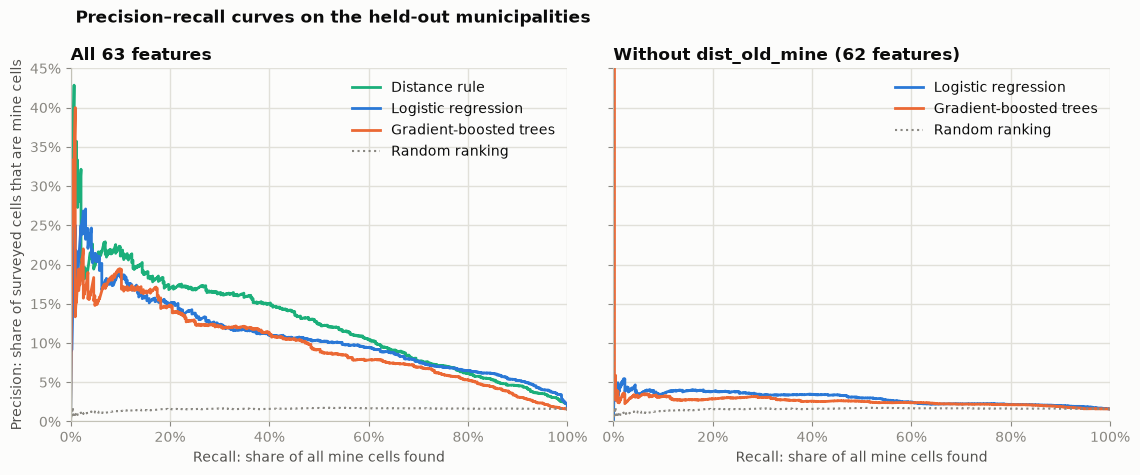

In [28]:
def pooled_curves(name):
    """Return pooled precision-recall and survey curves built from each municipality's own ranking."""
    share = share_ranked_above(ranking_scores[name])
    precision, recall, _ = precision_recall_curve(y, 1 - share)
    order = np.argsort(share.to_numpy(), kind="stable")
    surveyed = np.arange(1, len(order) + 1) / len(order)
    found = np.cumsum(y.to_numpy()[order]) / y.sum()
    return precision, recall, surveyed, found


curves = {name: pooled_curves(name) for name in RANKING_ORDER}
PANELS = {"All 63 features": ["Distance rule", "Logistic regression, 63 features",
                              "Gradient-boosted trees, 63 features", "Random ranking"],
          "Without dist_old_mine (62 features)": ["Logistic regression, 62 features",
                                                   "Gradient-boosted trees, 62 features", "Random ranking"]}


def colour_of(name):
    """Return the fixed colour of a ranking: one colour per model, whatever the feature set."""
    return COLOURS[name.split(",")[0]]


def short_label(name):
    """Return a ranking's name without its feature set, for panels that already state it."""
    return name.split(",")[0]


fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), sharey=True)
for ax, (panel, names) in zip(axes, PANELS.items()):
    for name in names:
        precision, recall, _, _ = curves[name]
        style = {"linestyle": ":", "linewidth": 1.5} if name == "Random ranking" else {}
        ax.plot(recall, precision, color=colour_of(name), label=short_label(name), **style)
    ax.set_title(panel)
    ax.set_xlabel("Recall: share of all mine cells found")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlim(0, 1)
    ax.legend(loc="upper right")
axes[0].set_ylabel("Precision: share of surveyed cells that are mine cells")
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylim(0, 0.45)  # the first few cells of each ranking, up to 100%, run off the top
fig.suptitle("Precision–recall curves on the held-out municipalities", x=0.07, ha="left",
             fontsize=12, fontweight="bold", color=INK)
fig.tight_layout()
for name in RANKING_ORDER:
    _, _, surveyed, found = curves[name]
    precision_at = []
    for target in (0.25, 0.5, 0.75):
        position = np.searchsorted(found, target)  # first cell at which the share of mine cells found reaches the target
        precision_at.append(found[position] * y.sum() / (position + 1))
    print(f"{name:<38} precision when 25% of mine cells are found: {precision_at[0]:.1%}   "
          f"50%: {precision_at[1]:.1%}   75%: {precision_at[2]:.1%}")
save_fig(fig, "03_precision_recall_curves.png")
plt.show()

With `dist_old_mine`, all three rankings keep precision well above the mine rate (1.6%) down most of the ranking. By the time a quarter of the mine cells have been found, 17.0% of the cells surveyed under the distance rule are mine cells, against 13.8% for the logistic regression and 12.8% for the trees; at half, 12.4%, 10.4% and 9.2%; at three quarters, 7.1%, 6.9% and 6.0%. The distance rule's curve lies at or above the models' over most of the range. Without `dist_old_mine`, precision is 3.8% (logistic regression) and 3.0% (trees) when a quarter of the mine cells have been found and 2.3% and 2.2% at three quarters, against 1.6% to 1.7% for the random ranking. At the very top of each ranking, precision rests on a handful of cells and jumps as high as 100%; the chart is cut at 45% so that the rest of the curves can be read.

### 7.4 Mine cells found against cells surveyed

The same rankings read as a survey plan: if a team surveyed each municipality's cells in the order of the ranking, what share of all mine cells would it have found after surveying a given share of the cells? The dashed line marks the top 10% scored in section 7.1.

Random ranking                         found after 10%: 6.7%   20%: 19.8%   30%: 31.2%
Distance rule                          found after 10%: 61.6%   20%: 78.8%   30%: 87.7%
Logistic regression, 63 features       found after 10%: 59.1%   20%: 80.5%   30%: 92.1%
Gradient-boosted trees, 63 features    found after 10%: 53.5%   20%: 74.7%   30%: 84.4%
Logistic regression, 62 features       found after 10%: 23.3%   20%: 42.6%   30%: 54.2%
Gradient-boosted trees, 62 features    found after 10%: 17.0%   20%: 34.4%   30%: 48.6%


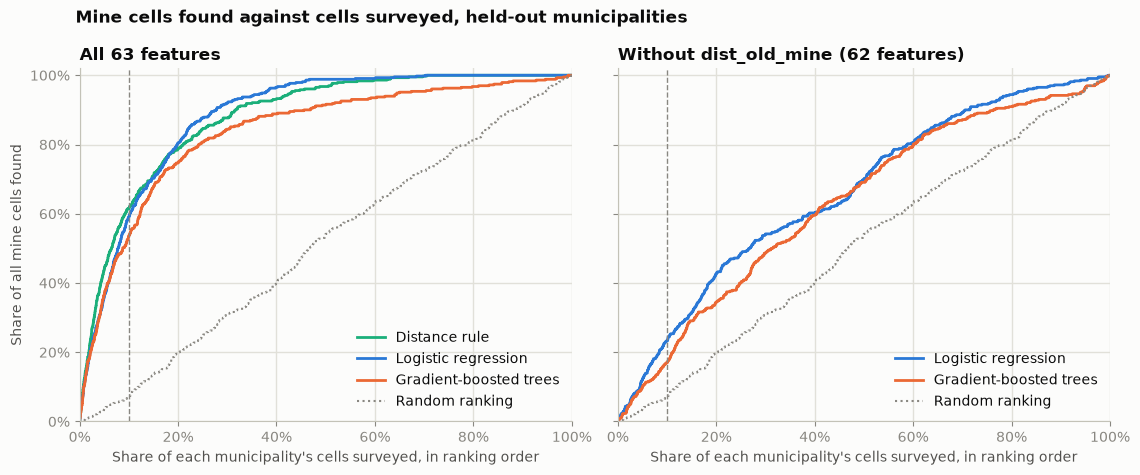

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), sharey=True)
for ax, (panel, names) in zip(axes, PANELS.items()):
    for name in names:
        _, _, surveyed, found = curves[name]
        style = {"linestyle": ":", "linewidth": 1.5} if name == "Random ranking" else {}
        ax.plot(surveyed, found, color=colour_of(name), label=short_label(name), **style)
    ax.axvline(TOP_SHARE, color=MUTED, linewidth=1, linestyle="--")
    ax.set_title(panel)
    ax.set_xlabel("Share of each municipality's cells surveyed, in ranking order")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlim(0, 1)
    ax.legend(loc="lower right")
axes[0].set_ylabel("Share of all mine cells found")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylim(0, 1.02)
fig.suptitle("Mine cells found against cells surveyed, held-out municipalities", x=0.07, ha="left",
             fontsize=12, fontweight="bold", color=INK)
fig.tight_layout()
for name in RANKING_ORDER:
    _, _, surveyed, found = curves[name]
    at = {share: found[np.searchsorted(surveyed, share, side="right") - 1] for share in (0.1, 0.2, 0.3)}
    print(f"{name:<38} found after 10%: {at[0.1]:.1%}   20%: {at[0.2]:.1%}   30%: {at[0.3]:.1%}")
save_fig(fig, "04_mine_cells_found.png")
plt.show()

Read as a survey plan, the rankings with `dist_old_mine` find most mine cells early. Surveying the top 10% of each municipality's cells finds 61.6% of all mine cells with the distance rule, 59.1% with the logistic regression and 53.5% with the trees. Deeper in the ranking the logistic regression overtakes the distance rule: after 20% of cells it has found 80.5% of mine cells (78.8% for the distance rule), and after 30%, 92.1% (87.7%). The trees stay behind both. Without `dist_old_mine`, the models find 23.3% and 17.0% of mine cells after 10% of cells and about half after 30% (54.2% and 48.6%), against 6.7%, 19.8% and 31.2% for a random order.

### 7.5 PR-AUC in each municipality

The mean hides wide differences between municipalities. Each row is one held-out municipality, with its number of mine cells; the grey tick marks its mine rate, about what a random ranking scores there.

,mine cells,mine rate,Distance rule,"Logistic regression, 63 features","Gradient-boosted trees, 63 features"
municipality,,,,,
Chigorodó,1,0.000,0.002,0.001,0.000
La Unión,1,0.001,0.333,1.000,1.000
San Roque,2,0.001,0.002,0.001,0.001
Sabanalarga,5,0.005,0.083,0.061,0.185
Alejandría,5,0.010,0.143,0.211,0.188
Abejorral,11,0.005,0.196,0.121,0.163
San Luis,16,0.009,0.192,0.209,0.109
Cocorná,26,0.027,0.160,0.162,0.192
San Francisco,27,0.019,0.384,0.057,0.166


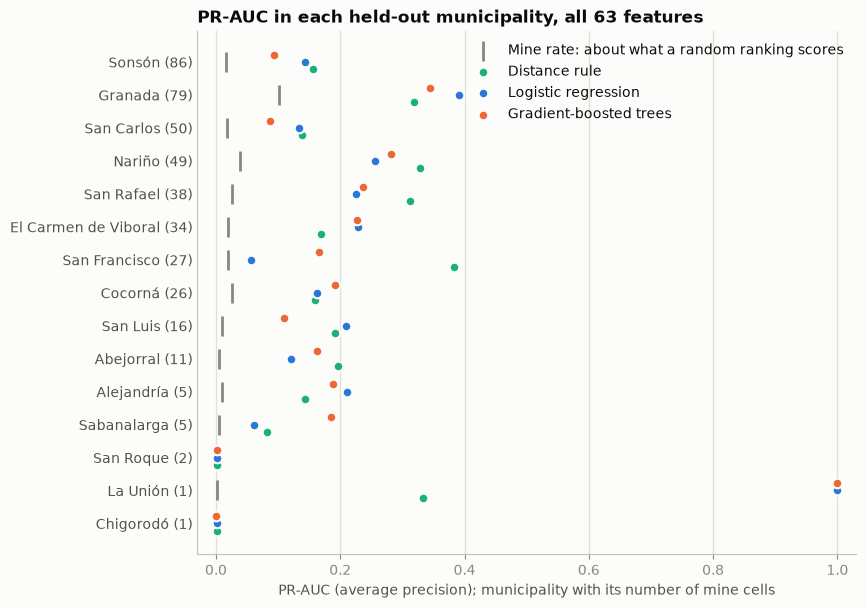

Logistic regression: higher PR-AUC than the distance rule in 6 of 15 municipalities
Gradient-boosted trees: higher PR-AUC than the distance rule in 6 of 15 municipalities

Where the municipalities with 1 or 2 mine cells put them (1 = first cell in the ranking):
  Chigorodó (2,937 cells): Distance rule 514; Logistic regression 840; Gradient-boosted trees 2444
  La Unión (678 cells): Distance rule 3; Logistic regression 1; Gradient-boosted trees 1
  San Roque (1,718 cells): Distance rule 922, 785; Logistic regression 1207, 1098; Gradient-boosted trees 1229, 203


In [30]:
SHOWN = ["Distance rule", "Logistic regression, 63 features", "Gradient-boosted trees, 63 features"]
table = pd.concat({name: per_municipality[name]["PR-AUC"] for name in SHOWN}, axis=1)
table.insert(0, "mine cells", per_municipality["Distance rule"]["mine cells"])
table.insert(1, "mine rate", by_municipality["mine_cells"] / by_municipality["cells"])
table = table.sort_values(["mine cells", "mine rate"])
display(table.round(3))

fig, ax = plt.subplots(figsize=(8.5, 6.8))
positions = np.arange(len(table))
OFFSETS = dict(zip(SHOWN, [-0.22, 0.0, 0.22]))  # small vertical offsets keep equal scores from hiding each other
ax.scatter(table["mine rate"], positions, marker="|", s=200, color=MUTED, linewidths=2,
           label="Mine rate: about what a random ranking scores", zorder=2)
for name in SHOWN:
    ax.scatter(table[name], positions + OFFSETS[name], s=48, color=colour_of(name), edgecolor=SURFACE,
               linewidth=1.5, label=short_label(name), zorder=3)
ax.set_yticks(positions, [f"{municipality} ({count})" for municipality, count in table["mine cells"].items()])
ax.tick_params(axis="y", length=0, labelcolor=INK_2)
ax.set_title("PR-AUC in each held-out municipality, all 63 features")
ax.set_xlabel("PR-AUC (average precision); municipality with its number of mine cells")
ax.set_xlim(-0.03, 1.03)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right")
save_fig(fig, "05_pr_auc_by_municipality.png")
plt.show()

for name in SHOWN[1:]:
    higher = int((table[name] > table["Distance rule"]).sum())
    print(f"{short_label(name)}: higher PR-AUC than the distance rule in {higher} of 15 municipalities")
print("\nWhere the municipalities with 1 or 2 mine cells put them (1 = first cell in the ranking):")
for municipality in table.index[table["mine cells"] <= 2]:
    cells = df[GROUP].map(DISPLAY_NAME) == municipality
    ranks = {name: ranking_scores[name][cells].rank(method="first", ascending=False)[y[cells] == 1].astype(int).tolist()
             for name in SHOWN}
    print(f"  {municipality} ({cells.sum():,} cells): "
          + "; ".join(f"{short_label(name)} {', '.join(map(str, r))}" for name, r in ranks.items()))

Results vary more between municipalities than between rankings: leaving out La Unión, each ranking's PR-AUC runs from about 0 to about 0.4. Each model scores higher than the distance rule in 6 of the 15 municipalities and lower in the other 9. The distance rule leads clearly in San Francisco (0.384, against 0.057 for the logistic regression and 0.166 for the trees), San Rafael and Nariño. Both models lead in La Unión, Granada, El Carmen de Viboral, Alejandría and Cocorná (the logistic regression there by 0.002); the logistic regression also leads in San Luis, and the trees in Sabanalarga.

The three municipalities with 1 or 2 mine cells show how fragile a score on so few cells is. In La Unión one cell decides the result: both models rank it first (PR-AUC 1.000) and the distance rule third (0.333). In Chigorodó and San Roque every ranking puts the mine cells hundreds of places down (the best are the distance rule's 514th of 2,937 cells in Chigorodó and the trees' 203rd of 1,718 in San Roque), so every PR-AUC there is close to zero.

## 8. Checks: one random split

How much would a random split flatter the models? The cells are split once at random, 80% for training and 20% for testing, keeping the 1.6% mine rate in both. The two models are tuned on the training cells with 3 random stratified folds, as one would without the municipal structure in mind, refitted, and scored on the test cells; the distance rule, which learns nothing, is scored on the same cells as a control. The scores are given two ways: pooled over all test cells, which is valid here because one model scores them all, and within each municipality, as in section 7. The within-municipality figure was added after the first run, so that the comparison with section 7 is like for like.

In [31]:
train_cells, test_cells = train_test_split(df.index, test_size=0.2, stratify=y, random_state=SEED)
random_inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
test_has_mines = df.loc[test_cells].groupby(GROUP)[TARGET].sum() > 0
print(f"Training cells: {len(train_cells):,} ({y[train_cells].sum()} mine cells); "
      f"test cells: {len(test_cells):,} ({y[test_cells].sum()} mine cells)")
print(f"Municipalities with at least one mine cell among the test cells: {test_has_mines.sum()}")

split_scores = {"Distance rule": -df.loc[test_cells, "dist_old_mine"]}
for model_name, (make, grid) in MODELS.items():
    search = GridSearchCV(make(FEATURES_63), grid, scoring="average_precision", cv=random_inner_cv, n_jobs=-1)
    search.fit(X.loc[train_cells], y[train_cells])
    split_scores[f"{model_name}, 63 features"] = pd.Series(search.predict_proba(X.loc[test_cells])[:, 1],
                                                           index=test_cells)
    print(f"{model_name}: chosen {search.best_params_}")

rows = []
for name, scores in split_scores.items():
    within = [average_precision_score(y[part.index], scores[part.index])
              for municipality, part in df.loc[test_cells].groupby(GROUP) if test_has_mines[municipality]]
    held_out = per_municipality[name]["PR-AUC"]
    same_municipalities = held_out[held_out.index.isin(test_has_mines[test_has_mines].index.map(DISPLAY_NAME))]
    rows.append({"ranking": name,
                 "random split: pooled PR-AUC": average_precision_score(y[test_cells], scores),
                 "random split: pooled ROC-AUC": roc_auc_score(y[test_cells], scores),
                 "random split: PR-AUC within municipalities (mean)": np.mean(within),
                 "held-out municipalities: PR-AUC (mean, same municipalities)": same_municipalities.mean()})
split_results = pd.DataFrame(rows).set_index("ranking")
split_results["random split ÷ held out"] = (split_results["random split: PR-AUC within municipalities (mean)"]
                                           / split_results["held-out municipalities: PR-AUC (mean, same municipalities)"])
split_results.round(3)

Training cells: 21,408 (344 mine cells); test cells: 5,353 (86 mine cells)
Municipalities with at least one mine cell among the test cells: 11


Logistic regression: chosen {'model__C': 0.01}


Gradient-boosted trees: chosen {'learning_rate': 0.3}


,random split: pooled PR-AUC,random split: pooled ROC-AUC,random split: PR-AUC within municipalities (mean),"held-out municipalities: PR-AUC (mean, same municipalities)",random split ÷ held out
ranking,,,,,
Distance rule,0.192,0.920,0.246,0.227,1.084
"Logistic regression, 63 features",0.249,0.940,0.258,0.194,1.325
"Gradient-boosted trees, 63 features",0.379,0.958,0.386,0.190,2.035


The random split flatters the trained models, and the trees most. Over the 11 municipalities with a mine cell among the test cells, the trees' mean PR-AUC within municipalities is 0.386 on random test cells against 0.190 when whole municipalities are held out, about twice as high, and the logistic regression's is 0.258 against 0.194, a third higher. The distance rule, which learns nothing, changes only from 0.227 to 0.246, because the test cells differ. Pooled over all test cells, the trees reach PR-AUC 0.379 and ROC-AUC 0.958. Inference: the trees gain most because they can pick up local patterns, such as the surroundings of known mine cells, which a random split leaves on both sides (section 3.3); tuned on random folds, the search also picked their highest learning rate, 0.3, the most flexible setting. A random split would have made the trees look clearly best; on new municipalities, they are not.

## 9. What the logistic regression weighs

To see what the logistic regression relies on, it is fitted once on all 15 municipalities, with `C` chosen by the same 3-fold grouped cross-validation. Because the continuous features are standardised, a weight is the change in the log-odds of a mine cell for one standard deviation of the feature (after the log, where one is applied); a negative weight on a distance means that nearer cells score higher. The weights describe associations in this data, not causes, and overlapping features share their effects (section 3.5).

In [32]:
FEATURE_LABELS = {
    "elevation": "Elevation", "rainfall": "Annual rainfall", "temperature": "Average temperature",
    "population_2012": "Population of the cell (log)", "No. Víctimas por Declaración": "Declared conflict victims (municipality)",
    "airports_dist": "Distance to airport (log)", "seaport_dist": "Distance to seaport (log)",
    "settlement_dist": "Distance to settlement (log)", "finance_dist": "Distance to financial institution (log)",
    "edu_dist": "Distance to school (log)", "buildings_dist": "Distance to building (log)",
    "waterways_dist": "Distance to waterway (log)", "coca_dist": "Distance to coca crops (log)",
    "dist_roads_t1": "Distance to primary road (log)", "dist_roads_t2": "Distance to secondary road (log)",
    "dist_roads_t3": "Distance to tertiary road (log)", "dist_old_mine": "Distance to past landmine event (log)",
    "soil_texture15_trans1": "Soil texture component 1", "soil_texture15_trans2": "Soil texture component 2",
    "nighttime_lights_2012": "Night-time lights (log)", "hist_mines": "Past landmine accidents (municipality)",
    "retro_pobl_tot": "Population (municipality)", "indrural": "Rural index (municipality)",
    "areaoficialkm2": "Area (municipality)", "altura": "Average altitude (municipality)",
    "discapital": "Distance to Medellín (municipality, log)", "pib_percapita_cons": "GDP per capita (municipality)"}

final_search = GridSearchCV(make_logistic_regression(FEATURES_63), LR_GRID, scoring="average_precision",
                            cv=INNER_CV, n_jobs=-1).fit(X, y, groups=groups)
final_model = final_search.best_estimator_
names = final_model.named_steps["preprocess"].get_feature_names_out()
lr_weights = pd.Series(final_model.named_steps["model"].coef_[0], index=names)
print(f"C chosen on all 15 municipalities: {final_search.best_params_['model__C']}")

continuous_weights = lr_weights[CONTINUOUS]
largest = continuous_weights.reindex(continuous_weights.abs().sort_values(ascending=False).index[:12])
display(largest.rename("weight").to_frame().assign(feature=lambda t: t.index.map(FEATURE_LABELS)).round(3))
onehot_weights = lr_weights[ONEHOT]
print("Largest one-hot weights (the change for belonging to the class, so not on the same scale):")
print(onehot_weights.reindex(onehot_weights.abs().sort_values(ascending=False).index[:5]).round(3).to_string())
print(f"\nElevation weight {lr_weights['elevation']:.3f}; temperature weight {lr_weights['temperature']:.3f}")

C chosen on all 15 municipalities: 0.001


,weight,feature
dist_old_mine,-1.464,Distance to past landmine event (log)
airports_dist,0.345,Distance to airport (log)
edu_dist,-0.199,Distance to school (log)
dist_roads_t3,0.180,Distance to tertiary road (log)
seaport_dist,0.177,Distance to seaport (log)
pib_percapita_cons,-0.176,GDP per capita (municipality)
population_2012,-0.164,Population of the cell (log)
soil_texture15_trans2,-0.163,Soil texture component 2
altura,0.163,Average altitude (municipality)
dist_roads_t2,0.128,Distance to secondary road (log)


Largest one-hot weights (the change for belonging to the class, so not on the same scale):
weather_Templado húmedo a muy húmedo    0.261
land_use_Forestal                       0.122
weather_Cálido húmedo a muy húmedo     -0.120
land_use_Agrícola                      -0.094
relief_Filas y vigas                    0.083

Elevation weight 0.115; temperature weight -0.063


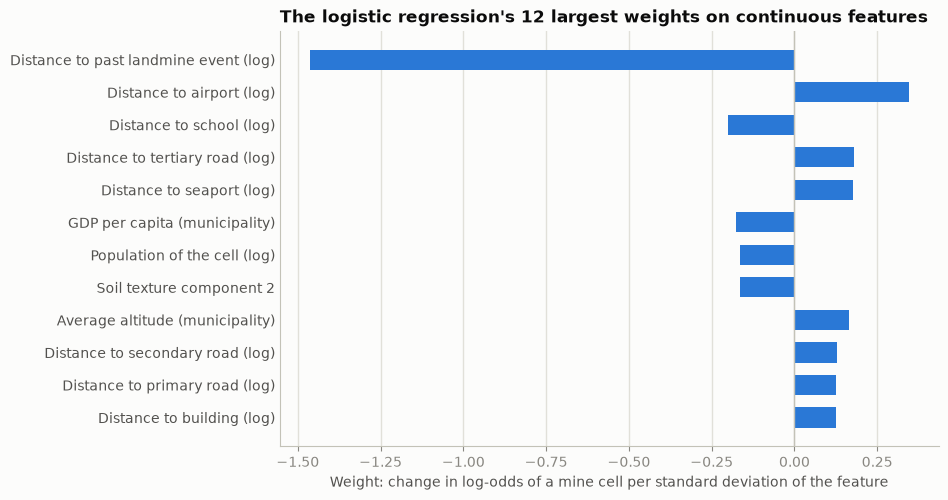

In [33]:
shown = largest.iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.4))
ax.barh([FEATURE_LABELS[c] for c in shown.index], shown, color=COLOURS["Logistic regression"], height=0.62)
ax.axvline(0, color=BASELINE, linewidth=1)
ax.set_title("The logistic regression's 12 largest weights on continuous features")
ax.set_xlabel("Weight: change in log-odds of a mine cell per standard deviation of the feature")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0, labelcolor=INK_2)
save_fig(fig, "06_logistic_regression_weights.png")
plt.show()

With `C` = 0.001, the logistic regression leans on one feature: the weight on the distance to past events (−1.46) is more than four times the next largest (0.35, the distance to an airport), and nearer a past event means a higher score. The other weights are small and mostly describe remoteness: higher scores for cells farther from airports, seaports, roads and buildings, with fewer people (−0.16), in municipalities with lower GDP per capita (−0.18) and higher average altitude (0.16), though also nearer schools (−0.20). Elevation and temperature, which overlap almost completely (section 3.5), carry small weights pointing the same way (higher, cooler cells score slightly higher: 0.12 and −0.06), so they do not cancel each other. Among the one-hot classes, one temperate, humid climate zone (0.26) and forest land (0.12) raise the score most. These are associations learned under strong regularisation, which shrinks every weight toward zero; they are not causes, and a weight can stand in for a feature it overlaps with.

## 10. Summary

This notebook framed landmine risk in 15 municipalities of Antioquia, Colombia, as supervised binary classification: from 63 open features, predict which of 26,761 grid cells of 500 × 500 m held mines (430 cells, 1.6%), so that a municipality's cells can be ranked for survey. Logistic regression and gradient-boosted trees, both weighted for the imbalance, were tuned and tested by holding out one municipality at a time and scored mainly by PR-AUC. With all features, neither model ranked a new municipality's cells reliably better than simply surveying the cells nearest a past landmine event first: over the 12 municipalities with at least 5 mine cells the distance rule's mean PR-AUC was 0.215, against 0.183 and 0.189, and it put 61.6% of all mine cells in the top 10% of cells, against 59.1% and 53.5%. Without the distance to past events the models still beat a random order but found only 23.3% and 17.0% of mine cells in the top 10%, and a random split of the cells, which leaves neighbouring mine cells on both sides, doubled the trees' PR-AUC, showing how much an easier test would have flattered them. The main limitations are that the labels record where demining found mines, which reflects where people searched and where events were reported as well as where mines lay; that the distance to past events may share a source with the labels; and that results from one region, with three municipalities holding only 1 or 2 mine cells, vary widely and may not transfer elsewhere.